In [2]:
#Import & Environment
import time
import numpy as np
import matplotlib.pyplot as plt
from numba import jit

## Champ de pression — équation de Poisson (Projet 1, section 2)

On cherche le champ de pression $p(x,y)$ associé au champ de vitesse imposé (partie A) :

$$u(x,y) = -U\sin\left(\frac{\pi x}{L}\right)\cos\left(\frac{\pi y}{L}\right), \qquad
v(x,y) = U\cos\left(\frac{\pi x}{L}\right)\sin\left(\frac{\pi y}{L}\right)$$

sur $x, y \in [0, L]$, avec $L = 0.3$ m, $U = 0.1$ m/s et $\rho_0 = 1.2$ kg/m³.

En prenant la divergence des équations de Navier-Stokes, on obtient une équation de **Poisson** (et non plus de Laplace) pour la pression :

$$\frac{\partial^2 p}{\partial x^2} + \frac{\partial^2 p}{\partial y^2} = f(x,y), \qquad
f(x,y) = \rho_0\left(\frac{\pi U}{L}\right)^2\left[\cos\left(\frac{2\pi x}{L}\right) + \cos\left(\frac{2\pi y}{L}\right)\right]$$

**Conditions aux limites** (Eq. 5 du sujet) :
- Neumann homogène $\partial p/\partial n = 0$ sur les bords **droit** ($x=L$) et **haut** ($y=L$) ;
- Dirichlet sur les bords **gauche** et **bas** :
$$p(0, y) = g(y) = \frac{1}{4}\rho_0 U^2\left(1 - \cos\frac{2\pi y}{L}\right), \qquad
p(x, 0) = g(x) = \frac{1}{4}\rho_0 U^2\left(1 - \cos\frac{2\pi x}{L}\right)$$

En discrétisant par différences finies centrées d'ordre 2 sur une grille régulière ($\Delta x$, $\Delta y$), le schéma itératif de **Jacobi** appliqué à cette équation de Poisson s'écrit, pour chaque point intérieur $(i,j)$ :

$$p_{i,j}^{n+1} = \frac{\Delta y^2\left(p_{i+1,j}^{n}+p_{i-1,j}^{n}\right) + \Delta x^2\left(p_{i,j+1}^{n}+p_{i,j-1}^{n}\right) - \Delta x^2 \Delta y^2\, f_{i,j}}{2\left(\Delta x^2 + \Delta y^2\right)}$$

c'est-à-dire le même schéma que pour Laplace, avec le terme source $f_{i,j}$ en plus.

**Question a)** : implémenter ce schéma pour $N_x = 31$ mailles (cellules) par côté et $N_t = 1000$ itérations, puis tracer le champ de pression obtenu.

### Solution analytique (pour comparaison)

Le sujet donne (section 3.2, Eq. 6-7) le coefficient de pression exact :

$$C_p^{exact} = \frac{1}{2}\left(2 - \cos\frac{2\pi x}{L} - \cos\frac{2\pi y}{L}\right), \qquad
C_p = \frac{p - p_0}{\frac12 \rho_0 U^2}, \quad p_0 = 0$$

En substituant, on obtient directement la solution analytique du champ de pression :

$$p_{exact}(x,y) = \frac{1}{4}\rho_0 U^2\left(2 - \cos\frac{2\pi x}{L} - \cos\frac{2\pi y}{L}\right)$$

On vérifie qu'elle satisfait bien l'équation de Poisson (Eq. 3-4) et les conditions aux limites (Eq. 5) : c'est exactement ce que le schéma de Jacobi doit approcher. Elle sert uniquement de référence pour juger la qualité de la solution numérique (en pratique, elle n'est presque jamais disponible).

In [3]:
# Paramètres physiques (section 2 du sujet)
L = 0.3       # taille du domaine carré [m]
U = 0.1       # vitesse caractéristique [m/s]
rho0 = 1.2    # masse volumique [kg/m^3]

# Grille : Nx mailles par côté -> Nx+1 points de grille
Nx = 31
nx = Nx + 1
ny = Nx + 1

dx = L / Nx
dy = L / Nx

x = np.linspace(0, L, nx)
y = np.linspace(0, L, ny)
X, Y = np.meshgrid(x, y)   # X[j,i] = x[i], Y[j,i] = y[j]

# Terme source f(x,y) de l'équation de Poisson (Eq. 4)
f = rho0 * (np.pi * U / L)**2 * (np.cos(2 * np.pi * X / L) + np.cos(2 * np.pi * Y / L))

# Solution analytique de référence (voir cellule markdown ci-dessus)
p_exact = 0.25 * rho0 * U**2 * (2 - np.cos(2 * np.pi * X / L) - np.cos(2 * np.pi * Y / L))


def initial_pressure_field(x, y, nx, ny):
    """
    Champ de pression initial : nul partout, sauf sur les deux bords
    Dirichlet (gauche et bas) où la condition g(x) / g(y) est imposée
    une fois pour toutes (Eq. 5).
    """
    p0 = np.zeros((ny, nx))
    p0[:, 0] = 0.25 * rho0 * U**2 * (1 - np.cos(2 * np.pi * y / L))   # p(0, y) = g(y), bord gauche
    p0[0, :] = 0.25 * rho0 * U**2 * (1 - np.cos(2 * np.pi * x / L))  # p(x, 0) = g(x), bord bas
    return p0


p = initial_pressure_field(x, y, nx, ny)

# Nombre d'itérations de Jacobi imposé par l'énoncé (question a)
Nt = 1000

# Seuil de réduction du résidu (question b, c, d)
eps = 1e-3
max_iter = 50000

In [4]:
@jit(nopython=True)
def poisson_jacobi(p, f, dx, dy, n_iter):
    """
    Résout l'équation de Poisson 2D  d2p/dx2 + d2p/dy2 = f  par la
    méthode itérative de Jacobi, pendant un nombre fixe d'itérations
    n_iter (question a : pas encore de critère de convergence).

    Le schéma appliqué à chaque point intérieur (i, j) est :

        p[j,i] = ( dy^2 * (p[j, i+1] + p[j, i-1])
                 + dx^2 * (p[j+1, i] + p[j-1, i])
                 - dx^2 * dy^2 * f[j, i] )
                 / (2 * (dx^2 + dy^2))

    qui correspond directement à la formule théorique de la cellule
    markdown ci-dessus (terme source f en plus du cas Laplace).

    Conditions aux limites :
      - Dirichlet à gauche (i=0) et en bas (j=0) : déjà imposées dans p
        avant l'appel, et jamais réécrites (la boucle ne parcourt que
        les points intérieurs, et les recopies Neumann ci-dessous
        évitent explicitement ces deux bords).
      - Neumann homogène (dp/dn = 0) à droite (i=nx-1) et en haut
        (j=ny-1) : approximées en recopiant la valeur du point voisin
        intérieur, à chaque itération. Aux deux coins où un bord
        Neumann rencontre un bord Dirichlet (bas-droite, haut-gauche),
        on ne recopie pas par-dessus la valeur de Dirichlet, qui doit
        rester exacte.

    La fonction est décorée avec @jit (Numba) : le code ci-dessous est
    exactement la traduction littérale de la formule mathématique, la
    compilation ne fait que le rendre rapide (indispensable dès qu'on
    raffine le maillage, question c).
    """
    for _ in range(n_iter):
        pn = p.copy()  # valeurs de l'itération précédente (n), utilisées pour calculer n+1

        # Boucle sur les points intérieurs uniquement (les CL sont traitées à part)
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p[j, i] = (dy**2 * (pn[j, i + 1] + pn[j, i - 1])
                           + dx**2 * (pn[j + 1, i] + pn[j - 1, i])
                           - dx**2 * dy**2 * f[j, i]) \
                          / (2 * (dx**2 + dy**2))

        # Conditions aux limites de Neumann homogène : dp/dn = 0
        # (on part de la ligne/colonne 1 pour ne pas écraser les coins
        #  Dirichlet situés en (j=0, i=-1) et (j=-1, i=0))
        p[1:, -1] = p[1:, -2]   # bord droit   (x = L)
        p[-1, 1:] = p[-2, 1:]   # bord haut    (y = L)

    return p

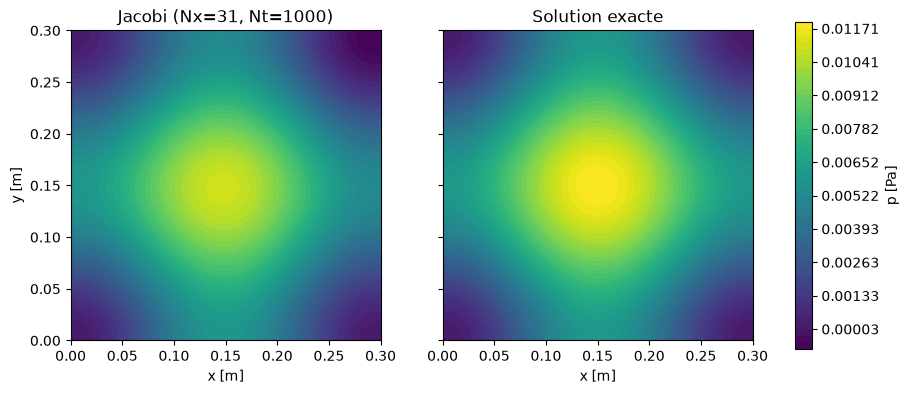

In [5]:
# Résolution (question a) : Nx = 31 mailles, Nt = 1000 itérations de Jacobi
p = poisson_jacobi(p, f, dx, dy, Nt)

# Comparaison côte à côte avec la solution analytique
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

levels = np.linspace(min(p.min(), p_exact.min()), max(p.max(), p_exact.max()), 50)

c0 = axes[0].contourf(X, Y, p, levels=levels, cmap="viridis")
axes[0].set_title(f"Jacobi (Nx={Nx}, Nt={Nt})")

c1 = axes[1].contourf(X, Y, p_exact, levels=levels, cmap="viridis")
axes[1].set_title("Solution exacte")

for ax in axes:
    ax.set_xlabel("x [m]")
    ax.set_aspect("equal")
axes[0].set_ylabel("y [m]")

fig.colorbar(c1, ax=axes, label="p [Pa]", shrink=0.85)
plt.show()

## Question b) — critère d'arrêt sur le résidu

On distingue deux quantités très différentes le long des itérations :

1. **La variation entre deux itérations successives**, $\|p^{n+1}-p^n\|$ : elle indique
   si l'algorithme *bouge encore*, c'est-à-dire s'il approche un point fixe de l'itération.
   Elle donne une idée de la **vitesse de convergence** de la méthode, mais un schéma peut
   très bien se figer (variation quasi nulle) sans que $p$ vérifie l'équation.

2. **Le résidu** $r = b - Ax$, où $Ax=b$ est l'équation de Poisson discrétisée
   ($b=f$ ici) : on réinjecte le champ $p$ courant dans l'équation qu'on cherche à
   résoudre pour chaque point intérieur $(i,j)$ :
   $$r_{i,j} = f_{i,j} - \left(\frac{p_{i+1,j}-2p_{i,j}+p_{i-1,j}}{\Delta x^2}
   + \frac{p_{i,j+1}-2p_{i,j}+p_{i,j-1}}{\Delta y^2}\right)$$
   Si $r \to 0$, $p$ vérifie de mieux en mieux l'EDP : c'est le véritable indicateur de
   convergence vers **la bonne solution**, pas seulement vers un point fixe.

L'énoncé demande d'arrêter les itérations lorsque le résidu initial a été réduit de
plusieurs ordres de grandeur : $\|r\| < \varepsilon \|r_0\|$, avec $\varepsilon = 10^{-3}$
et $r_0$ le résidu calculé avant la première itération. On garde les deux indicateurs :
le résidu pour piloter l'arrêt, et la variation $\|p^{n+1}-p^n\|$ pour comparer visuellement
la vitesse à laquelle l'algorithme progresse.

In [6]:
@jit(nopython=True)
def poisson_residual(p, f, dx, dy):
    """
    Calcule le résidu r = b - Ax de l'équation de Poisson discrétisée
    (ici b = f), c'est-à-dire à quel point le champ p courant vérifie
    (ou non) l'équation d2p/dx2 + d2p/dy2 = f en chaque point intérieur :

        r[j,i] = f[j,i] - ( (p[j,i+1] - 2*p[j,i] + p[j,i-1]) / dx^2
                           + (p[j+1,i] - 2*p[j,i] + p[j-1,i]) / dy^2 )

    Le résidu n'est défini qu'aux points intérieurs (l'équation ne
    s'applique pas sur les bords) ; il est laissé à zéro ailleurs.
    """
    r = np.zeros_like(p)

    for j in range(1, p.shape[0] - 1):
        for i in range(1, p.shape[1] - 1):
            d2p_dx2 = (p[j, i + 1] - 2 * p[j, i] + p[j, i - 1]) / dx**2
            d2p_dy2 = (p[j + 1, i] - 2 * p[j, i] + p[j - 1, i]) / dy**2
            r[j, i] = f[j, i] - (d2p_dx2 + d2p_dy2)

    return r


@jit(nopython=True)
def l2_norm(a):
    """Norme L2 (racine de la somme des carrés) d'un tableau."""
    return np.sqrt(np.sum(a**2))


@jit(nopython=True)
def poisson_jacobi_residual(p, f, dx, dy, eps, max_iter):
    """
    Résout l'équation de Poisson par la méthode de Jacobi (même schéma
    que poisson_jacobi), mais arrête les itérations lorsque le résidu
    a été réduit d'un facteur eps par rapport au résidu initial r0 :

        ||r|| < eps * ||r0||

    Renvoie le champ p, le nombre d'itérations effectuées, ainsi que
    les historiques de deux indicateurs (voir cellule markdown
    ci-dessus) :
      - delta_history : variation ||p^(n+1) - p^n|| à chaque itération,
      - res_ratio_history : résidu normalisé ||r|| / ||r0||.

    Note : le corps de la boucle est identique à poisson_jacobi ; seul
    le critère d'arrêt change. La fonction est compilée avec Numba
    (@jit) pour rendre les maillages fins (question c) exploitables :
    cela ne modifie ni la formule ni sa lisibilité, seulement sa vitesse
    d'exécution.
    """
    r0_norm = l2_norm(poisson_residual(p, f, dx, dy))

    delta_history = np.zeros(max_iter)
    res_ratio_history = np.zeros(max_iter)

    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        pn = p.copy()  # valeurs de l'itération précédente (n)

        # Boucle sur les points intérieurs uniquement (même schéma que poisson_jacobi)
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p[j, i] = (dy**2 * (pn[j, i + 1] + pn[j, i - 1])
                           + dx**2 * (pn[j + 1, i] + pn[j - 1, i])
                           - dx**2 * dy**2 * f[j, i]) \
                          / (2 * (dx**2 + dy**2))

        # Conditions aux limites de Neumann homogène (dp/dn = 0), coins Dirichlet préservés
        p[1:, -1] = p[1:, -2]   # bord droit (x = L)
        p[-1, 1:] = p[-2, 1:]   # bord haut  (y = L)

        # Indicateur 1 : variation entre deux itérations successives (norme L2)
        delta_history[iteration] = l2_norm(p - pn)

        # Indicateur 2 : résidu normalisé de l'équation discrétisée
        res_ratio = l2_norm(poisson_residual(p, f, dx, dy)) / r0_norm
        res_ratio_history[iteration] = res_ratio

        iteration += 1

    return p, iteration, delta_history[:iteration], res_ratio_history[:iteration]

Convergence obtenue en 2690 itérations (contre Nt=1000 imposé en a).
  résidu final   ||r||/||r0||        = 9.996e-04  (seuil eps = 1e-03)
  variation finale ||p^(n+1)-p^n||   = 7.673e-06


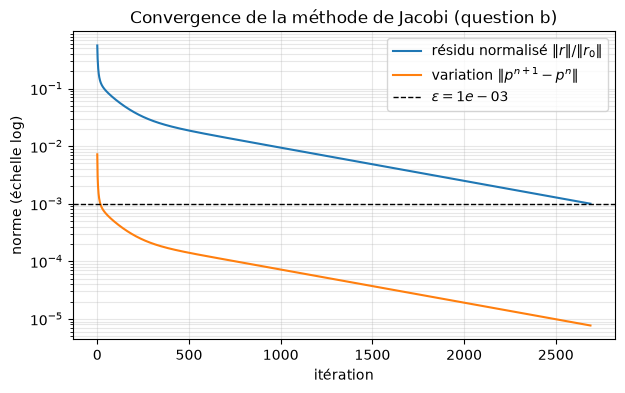

In [7]:
# Question b) : résolution pilotée par le résidu (eps = 1e-3), champ initial repartant de zéro
p_b = initial_pressure_field(x, y, nx, ny)
p_b, n_iter_b, delta_history, res_ratio_history = poisson_jacobi_residual(p_b, f, dx, dy, eps, max_iter)

print(f"Convergence obtenue en {n_iter_b} itérations (contre Nt={Nt} imposé en a).")
print(f"  résidu final   ||r||/||r0||        = {res_ratio_history[-1]:.3e}  (seuil eps = {eps:.0e})")
print(f"  variation finale ||p^(n+1)-p^n||   = {delta_history[-1]:.3e}")

# Évolution des deux critères le long des itérations (échelle semi-log)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(res_ratio_history, label=r"résidu normalisé $\|r\|/\|r_0\|$")
ax.semilogy(delta_history, label=r"variation $\|p^{n+1}-p^n\|$")
ax.axhline(eps, color="k", linestyle="--", linewidth=1, label=rf"$\varepsilon = {eps:.0e}$")
ax.set_xlabel("itération")
ax.set_ylabel("norme (échelle log)")
ax.set_title("Convergence de la méthode de Jacobi (question b)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

## Question c) — Raffinement du maillage (Nx = 101)

On reprend exactement le même calcul (résidu, $\varepsilon=10^{-3}$) mais avec un maillage
beaucoup plus fin : $N_x=101$ mailles par côté au lieu de 31, soit $102\times102$ points
au lieu de $32\times32$ (environ $10.6$ fois plus de points).

**Pourquoi cela va être beaucoup plus lent ?** Deux effets se cumulent :

1. **Coût par itération** : une itération de Jacobi met à jour tous les points intérieurs,
   donc son coût est $O(N_x^2)$. Passer de $N_x=31$ à $N_x=101$ multiplie déjà le travail
   par itération par $\approx 10.6$.
2. **Nombre d'itérations nécessaires** : le schéma de Jacobi converge d'autant plus
   lentement que la grille est fine. Le facteur de réduction de l'erreur à chaque itération
   (rayon spectral de la matrice d'itération) vaut approximativement
   $$\rho_{Jacobi} \approx 1 - \frac{\pi^2}{2}\left(\frac{\Delta x}{L}\right)^2 = 1 - \frac{\pi^2}{2 N_x^2}$$
   c'est-à-dire une valeur *de plus en plus proche de 1* quand $N_x$ augmente : chaque
   itération ne réduit l'erreur que d'une fraction infime. Le nombre d'itérations requis pour
   atteindre un critère donné croît donc comme $O(N_x^2)$.

En combinant les deux effets, le **coût total** de la méthode de Jacobi croît comme
$O(N_x^4)$ : doubler la résolution spatiale multiplie le temps de calcul par ~16. C'est la
raison pour laquelle Jacobi devient rapidement impraticable sur des maillages fins — et la
motivation des méthodes de Gauss-Seidel et SOR (question d), qui convergent en beaucoup
moins d'itérations.

*(Les fonctions ci-dessus sont compilées avec Numba (`@jit`) : sans cela, les boucles
Python pures rendraient le cas $N_x=101$ bien trop lent à exécuter ici — plusieurs minutes
au lieu de quelques secondes — alors que le code reste rigoureusement identique.)*

In [8]:
def build_problem(Nx):
    """
    Construit la grille, le terme source f, la solution analytique et
    le champ initial (avec conditions de Dirichlet) pour un nombre de
    mailles Nx donné. Regroupe ce qui était fait "à la main" dans la
    cellule de paramètres, pour pouvoir facilement comparer plusieurs
    maillages (questions c, d, ...).
    """
    nx, ny = Nx + 1, Nx + 1
    dx = dy = L / Nx

    x = np.linspace(0, L, nx)
    y = np.linspace(0, L, ny)
    X, Y = np.meshgrid(x, y)

    f = rho0 * (np.pi * U / L)**2 * (np.cos(2 * np.pi * X / L) + np.cos(2 * np.pi * Y / L))
    p_exact = 0.25 * rho0 * U**2 * (2 - np.cos(2 * np.pi * X / L) - np.cos(2 * np.pi * Y / L))
    p0 = initial_pressure_field(x, y, nx, ny)

    return dx, dy, X, Y, f, p_exact, p0


# Comparaison Nx = 31 (question b) vs Nx = 101 (question c), même critère eps
results_c = {}
for Nx_c in (31, 101):
    dx_c, dy_c, X_c, Y_c, f_c, p_exact_c, p0_c = build_problem(Nx_c)

    t0 = time.time()
    p_c, n_iter_c, delta_c, res_ratio_c = poisson_jacobi_residual(p0_c, f_c, dx_c, dy_c, eps, max_iter)
    elapsed_c = time.time() - t0

    results_c[Nx_c] = dict(p=p_c, X=X_c, Y=Y_c, p_exact=p_exact_c,
                            n_iter=n_iter_c, time=elapsed_c,
                            res_ratio=res_ratio_c)
    print(f"Nx={Nx_c:4d} : {n_iter_c:6d} itérations, {elapsed_c:6.3f} s "
          f"({elapsed_c/n_iter_c*1e3:.4f} ms/itération)")

Nx=  31 :   2690 itérations,  0.014 s (0.0053 ms/itération)
Nx= 101 :  13511 itérations,  0.773 s (0.0572 ms/itération)


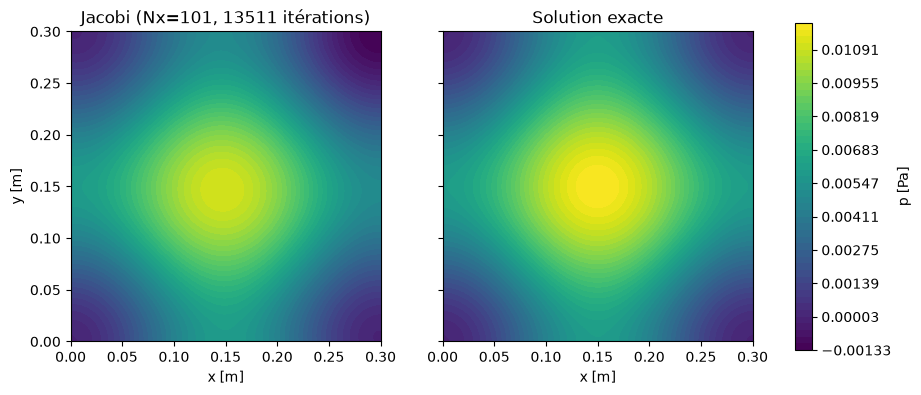

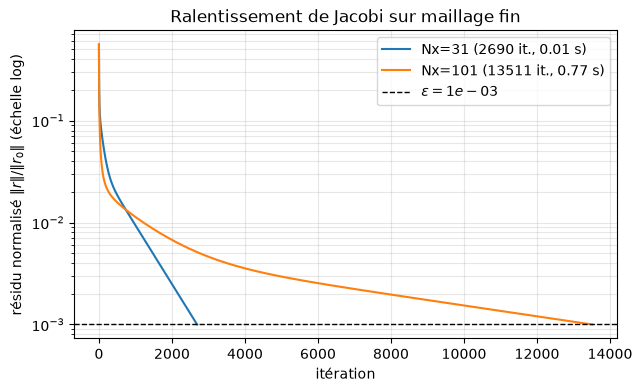

In [9]:
# Champ de pression obtenu à Nx=101, comparé à la solution exacte
res101 = results_c[101]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
levels = np.linspace(min(res101["p"].min(), res101["p_exact"].min()),
                      max(res101["p"].max(), res101["p_exact"].max()), 50)

axes[0].contourf(res101["X"], res101["Y"], res101["p"], levels=levels, cmap="viridis")
axes[0].set_title(f"Jacobi (Nx=101, {res101['n_iter']} itérations)")
c1 = axes[1].contourf(res101["X"], res101["Y"], res101["p_exact"], levels=levels, cmap="viridis")
axes[1].set_title("Solution exacte")
for ax in axes:
    ax.set_xlabel("x [m]")
    ax.set_aspect("equal")
axes[0].set_ylabel("y [m]")
fig.colorbar(c1, ax=axes, label="p [Pa]", shrink=0.85)
plt.show()

# Convergence du résidu : Nx=31 vs Nx=101 (même critère eps)
fig, ax = plt.subplots(figsize=(7, 4))
for Nx_c, res in results_c.items():
    ax.semilogy(res["res_ratio"], label=f"Nx={Nx_c} ({res['n_iter']} it., {res['time']:.2f} s)")
ax.axhline(eps, color="k", linestyle="--", linewidth=1, label=rf"$\varepsilon={eps:.0e}$")
ax.set_xlabel("itération")
ax.set_ylabel(r"résidu normalisé $\|r\|/\|r_0\|$ (échelle log)")
ax.set_title("Ralentissement de Jacobi sur maillage fin")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

## Question d) — Gauss-Seidel et SOR

**Gauss-Seidel** reprend exactement la même formule que Jacobi, mais utilise
*immédiatement* les valeurs déjà mises à jour au cours du balayage, au lieu d'attendre la
fin de l'itération complète (pas de tableau `pn` séparé) :

$$p_{i,j} \leftarrow \frac{\Delta y^2\left(p_{i+1,j}+p_{i-1,j}\right) + \Delta x^2\left(p_{i,j+1}+p_{i,j-1}\right) - \Delta x^2 \Delta y^2\, f_{i,j}}{2\left(\Delta x^2 + \Delta y^2\right)}$$

où, au moment de calculer $p_{i,j}$, les points $p_{i-1,j}$ et $p_{i,j-1}$ (déjà balayés)
sont ceux de l'itération **courante** $n+1$, alors que $p_{i+1,j}$ et $p_{i,j+1}$ (pas encore
balayés) sont encore ceux de l'itération $n$. L'information se propage donc plus vite dans
le domaine, d'où une convergence plus rapide (environ deux fois moins d'itérations que
Jacobi).

**SOR** (*Successive Over-Relaxation*) pousse l'idée plus loin en sur-relaxant la
correction de Gauss-Seidel d'un facteur $\omega$ :

$$p_{i,j} \leftarrow (1-\omega)\, p_{i,j} + \omega\, p_{i,j}^{GS}$$

où $p_{i,j}^{GS}$ est la valeur que donnerait Gauss-Seidel. Pour $\omega=1$ on retrouve
Gauss-Seidel ; $1 < \omega < 2$ accélère la convergence. Le facteur optimal pour l'équation
de Poisson sur un maillage carré (formule classique du cours) est :

$$\omega_{opt} = \frac{2}{1+\sin(\pi/N_x)}$$

In [10]:
@jit(nopython=True)
def poisson_gauss_seidel(p, f, dx, dy, eps, max_iter):
    """
    Résout l'équation de Poisson par la méthode de Gauss-Seidel :
    même formule que poisson_jacobi_residual, mais p est mis à jour
    « en place » pendant le balayage (pas de copie pn séparée), si bien
    que chaque nouvelle valeur utilise déjà les voisins qui viennent
    d'être recalculés à l'itération courante.
    """
    r0_norm = l2_norm(poisson_residual(p, f, dx, dy))

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p[j, i] = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                           + dx**2 * (p[j + 1, i] + p[j - 1, i])
                           - dx**2 * dy**2 * f[j, i]) \
                          / (2 * (dx**2 + dy**2))

        p[1:, -1] = p[1:, -2]   # bord droit (x = L)
        p[-1, 1:] = p[-2, 1:]   # bord haut  (y = L)

        res_ratio = l2_norm(poisson_residual(p, f, dx, dy)) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]


@jit(nopython=True)
def poisson_sor(p, f, dx, dy, omega, eps, max_iter):
    """
    Résout l'équation de Poisson par SOR : identique à Gauss-Seidel,
    mais la nouvelle valeur est une combinaison pondérée entre
    l'ancienne valeur p_old et la valeur de Gauss-Seidel p_gs :

        p[j,i] = (1 - omega) * p_old + omega * p_gs

    omega = 1 redonne exactement Gauss-Seidel.
    """
    r0_norm = l2_norm(poisson_residual(p, f, dx, dy))

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p_gs = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                        + dx**2 * (p[j + 1, i] + p[j - 1, i])
                        - dx**2 * dy**2 * f[j, i]) \
                       / (2 * (dx**2 + dy**2))
                p[j, i] = (1 - omega) * p[j, i] + omega * p_gs

        p[1:, -1] = p[1:, -2]   # bord droit (x = L)
        p[-1, 1:] = p[-2, 1:]   # bord haut  (y = L)

        res_ratio = l2_norm(poisson_residual(p, f, dx, dy)) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]

In [11]:
# Pré-compilation Numba (à faire une fois, hors chronométrage : sinon le premier
# appel de chaque fonction inclurait le temps de compilation, faussant la comparaison)
_dx0, _dy0, _, _, _f0, _, _p0 = build_problem(4)
poisson_jacobi_residual(_p0.copy(), _f0, _dx0, _dy0, eps, 1)
poisson_gauss_seidel(_p0.copy(), _f0, _dx0, _dy0, eps, 1)
poisson_sor(_p0.copy(), _f0, _dx0, _dy0, 1.5, eps, 1)

# Comparaison Jacobi / Gauss-Seidel / SOR, même critère eps, pour deux maillages
print(f"{'Nx':>4} {'méthode':<14} {'itérations':>11} {'temps [s]':>10} {'erreur vs exact':>16}")
print("-" * 60)

comparison = {}
for Nx_d in (31, 101):
    dx_d, dy_d, X_d, Y_d, f_d, p_exact_d, p0_d = build_problem(Nx_d)
    omega = 2 / (1 + np.sin(np.pi / Nx_d))

    methods = {
        "Jacobi": lambda: poisson_jacobi_residual(p0_d.copy(), f_d, dx_d, dy_d, eps, max_iter)[:2],
        "Gauss-Seidel": lambda: poisson_gauss_seidel(p0_d.copy(), f_d, dx_d, dy_d, eps, max_iter)[:2],
        f"SOR (w={omega:.3f})": lambda: poisson_sor(p0_d.copy(), f_d, dx_d, dy_d, omega, eps, max_iter)[:2],
    }

    for name, solve in methods.items():
        t0 = time.time()
        p_sol, n_iter_sol = solve()
        elapsed = time.time() - t0
        error = np.linalg.norm(p_sol - p_exact_d) / np.linalg.norm(p_exact_d)
        comparison[(Nx_d, name)] = dict(n_iter=n_iter_sol, time=elapsed, error=error)
        print(f"{Nx_d:>4} {name:<14} {n_iter_sol:>11d} {elapsed:>10.3f} {error:>16.2e}")
    print()

  Nx méthode         itérations  temps [s]  erreur vs exact
------------------------------------------------------------
  31 Jacobi                2690      0.019         1.29e-01
  31 Gauss-Seidel          1368      0.014         1.29e-01
  31 SOR (w=1.816)          153      0.002         1.30e-01

 101 Jacobi               13511      0.773         1.15e-01
 101 Gauss-Seidel          6740      0.712         1.15e-01
 101 SOR (w=1.940)          178      0.023         1.06e-01



**Commentaire.** Les trois méthodes convergent vers *le même* champ discret (même $\varepsilon$,
même erreur par rapport à la solution exacte à Nx fixé : cette erreur ne dépend que du
maillage, pas de l'algorithme utilisé pour résoudre le système linéaire). Ce qui change
radicalement, c'est le **nombre d'itérations** :

- **Gauss-Seidel** converge en environ **deux fois moins d'itérations** que Jacobi (cohérent
  avec la théorie : son rayon spectral est le carré de celui de Jacobi, $\rho_{GS}=\rho_{Jacobi}^2$).
- **SOR** avec le $\omega$ optimal est spectaculairement plus rapide — un ordre de grandeur
  de moins d'itérations que Gauss-Seidel, et l'écart **se creuse encore** quand le maillage
  est raffiné : le nombre d'itérations de SOR croît en $O(N_x)$ contre $O(N_x^2)$ pour
  Jacobi/Gauss-Seidel. C'est exactement pour cette raison que la méthode reste utilisable sur
  des maillages fins là où Jacobi (question c) devient prohibitif.
- Le **temps de calcul** suit globalement le nombre d'itérations (le coût par itération est
  comparable pour les trois méthodes, à O(Nx²) près), sauf que Gauss-Seidel et SOR ne
  nécessitent pas la copie `pn = p.copy()` à chaque itération, ce qui les avantage encore
  légèrement à nombre d'itérations égal.

## Question e) — Optimisation (simple, pas agressive)

Avant de changer quoi que ce soit, on mesure. Deux essais :

**Essai 1 (rejeté) : vectoriser la mise à jour de Jacobi avec du slicing numpy**
au lieu de la double boucle `for`. C'est le réflexe "manuel de CFD" classique (Jacobi n'a
pas de dépendance entre points, donc rien n'empêche de l'écrire sans boucle). Résultat
mesuré à $N_x=101$, 5000 itérations : boucle `@jit` **0.06 s** contre version vectorisée
`numpy` **0.17 s** — la version "vectorisée" est **3× plus lente** ! En effet chaque slice
(`pn[1:-1,2:]`, `pn[1:-1,:-2]`, ...) alloue un tableau temporaire à chaque itération, alors
que la boucle compilée par Numba ne fait aucune allocation et est traduite en code machine
aussi efficace qu'en C. **On garde donc la boucle `for` telle quelle** : elle est déjà
optimale une fois compilée, la "vectoriser" n'aurait fait qu'ajouter du travail inutile.

**Essai 2 (adopté) : supprimer les allocations mémoire redondantes.** Deux endroits où on
alloue un tableau à chaque itération alors que ce n'est pas nécessaire :

1. `poisson_residual` construit un tableau `r` complet uniquement pour calculer sa norme
   juste après (`l2_norm(poisson_residual(...))`). On peut cumuler directement la somme
   des carrés dans la boucle et ne renvoyer que le scalaire : plus besoin d'allouer `r`.
   Mesuré (à l'intérieur d'une boucle compilée, donc hors coût d'appel Python) :
   **29.9 → 19.9 µs/appel**, soit environ **1.5× plus rapide**, gain qui compte car cette
   fonction est appelée à *chaque* itération des *trois* méthodes.
2. Dans `poisson_jacobi_residual`, `pn = p.copy()` réalloue un tableau à chaque itération.
   En allouant `pn` **une seule fois** avant la boucle puis en échangeant les rôles de `p`
   et `pn` (`p, pn = pn, p`) après chaque sweep, on obtient exactement le même résultat sans
   jamais réallouer. Mesuré à $N_x=101$, 10000 itérations : **0.16 s → 0.12 s** (~30 % plus
   rapide). Gauss-Seidel et SOR n'ont pas ce problème : ils modifient déjà `p` en place, sans
   tableau `pn`.

On ne pousse pas plus loin (pas de réécriture en C, pas de parallélisation multi-cœur,
pas de solveur direct) : l'énoncé demande une optimisation *raisonnable*, pas la plus
agressive possible, et le code doit rester lisible et modifiable.

In [12]:
@jit(nopython=True)
def residual_norm(p, f, dx, dy):
    """
    Norme L2 du résidu r = b - Ax, calculée DIRECTEMENT (sans jamais
    construire le tableau r complet comme le faisait poisson_residual) :
    on cumule la somme des carrés au fil de la boucle et on ne renvoie
    que le scalaire final. Économise une allocation de tableau à
    chaque appel — appelée à chaque itération des trois méthodes.
    """
    s = 0.0
    for j in range(1, p.shape[0] - 1):
        for i in range(1, p.shape[1] - 1):
            d2p_dx2 = (p[j, i + 1] - 2 * p[j, i] + p[j, i - 1]) / dx**2
            d2p_dy2 = (p[j + 1, i] - 2 * p[j, i] + p[j - 1, i]) / dy**2
            r = f[j, i] - (d2p_dx2 + d2p_dy2)
            s += r * r
    return np.sqrt(s)


@jit(nopython=True)
def poisson_jacobi_opt(p, f, dx, dy, eps, max_iter):
    """
    Version optimisée de poisson_jacobi_residual : même formule, même
    résultat, mais le buffer pn est alloué UNE SEULE fois avant la
    boucle. À chaque itération, on écrit les nouvelles valeurs dans pn
    (en lisant p), puis on échange les rôles p <-> pn : p pointe alors
    vers le tableau qui vient d'être calculé, pn vers l'ancien buffer
    (qui sera réécrit au tour suivant). Plus aucune allocation après
    la première itération.
    """
    r0_norm = residual_norm(p, f, dx, dy)

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0
    pn = p.copy()  # buffer alloué une seule fois

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                pn[j, i] = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                            + dx**2 * (p[j + 1, i] + p[j - 1, i])
                            - dx**2 * dy**2 * f[j, i]) \
                           / (2 * (dx**2 + dy**2))

        pn[1:, -1] = pn[1:, -2]   # bord droit (x = L)
        pn[-1, 1:] = pn[-2, 1:]   # bord haut  (y = L)

        p, pn = pn, p   # échange de rôles, sans copie

        res_ratio = residual_norm(p, f, dx, dy) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]


@jit(nopython=True)
def poisson_gauss_seidel_opt(p, f, dx, dy, eps, max_iter):
    """Identique à poisson_gauss_seidel, avec residual_norm fusionné (pas de tableau r)."""
    r0_norm = residual_norm(p, f, dx, dy)

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p[j, i] = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                           + dx**2 * (p[j + 1, i] + p[j - 1, i])
                           - dx**2 * dy**2 * f[j, i]) \
                          / (2 * (dx**2 + dy**2))

        p[1:, -1] = p[1:, -2]
        p[-1, 1:] = p[-2, 1:]

        res_ratio = residual_norm(p, f, dx, dy) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]


@jit(nopython=True)
def poisson_sor_opt(p, f, dx, dy, omega, eps, max_iter):
    """Identique à poisson_sor, avec residual_norm fusionné (pas de tableau r)."""
    r0_norm = residual_norm(p, f, dx, dy)

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p_gs = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                        + dx**2 * (p[j + 1, i] + p[j - 1, i])
                        - dx**2 * dy**2 * f[j, i]) \
                       / (2 * (dx**2 + dy**2))
                p[j, i] = (1 - omega) * p[j, i] + omega * p_gs

        p[1:, -1] = p[1:, -2]
        p[-1, 1:] = p[-2, 1:]

        res_ratio = residual_norm(p, f, dx, dy) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]

In [13]:
# Warm-up (compilation Numba, hors chronométrage)
_dx0, _dy0, _, _, _f0, _, _p0 = build_problem(4)
poisson_jacobi_opt(_p0.copy(), _f0, _dx0, _dy0, eps, 1)
poisson_gauss_seidel_opt(_p0.copy(), _f0, _dx0, _dy0, eps, 1)
poisson_sor_opt(_p0.copy(), _f0, _dx0, _dy0, 1.5, eps, 1)

# On répète la comparaison de la question d) avec le code optimisé
print(f"{'Nx':>4} {'méthode':<14} {'itérations':>11} {'temps [s]':>10} {'vs question d)':>15}")
print("-" * 65)

for Nx_d in (31, 101):
    dx_d, dy_d, X_d, Y_d, f_d, p_exact_d, p0_d = build_problem(Nx_d)
    omega = 2 / (1 + np.sin(np.pi / Nx_d))

    methods_opt = {
        "Jacobi": lambda: poisson_jacobi_opt(p0_d.copy(), f_d, dx_d, dy_d, eps, max_iter)[:2],
        "Gauss-Seidel": lambda: poisson_gauss_seidel_opt(p0_d.copy(), f_d, dx_d, dy_d, eps, max_iter)[:2],
        f"SOR (w={omega:.3f})": lambda: poisson_sor_opt(p0_d.copy(), f_d, dx_d, dy_d, omega, eps, max_iter)[:2],
    }

    for name, solve in methods_opt.items():
        t0 = time.time()
        p_sol, n_iter_sol = solve()
        elapsed = time.time() - t0
        t_before = comparison[(Nx_d, name)]["time"]
        speedup = t_before / elapsed if elapsed > 0 else float("nan")
        print(f"{Nx_d:>4} {name:<14} {n_iter_sol:>11d} {elapsed:>10.4f} {speedup:>13.2f}x")
    print()

  Nx méthode         itérations  temps [s]  vs question d)
-----------------------------------------------------------------
  31 Jacobi                2690     0.0071          2.72x
  31 Gauss-Seidel          1368     0.0096          1.49x
  31 SOR (w=1.816)          153     0.0000           nanx

 101 Jacobi               13511     0.4560          1.69x
 101 Gauss-Seidel          6740     0.6353          1.12x
 101 SOR (w=1.940)          178     0.0220          1.02x



## Question f) — Force de pression sur le bord droit, $\langle p \rangle$

### Ce que dit l'énoncé, expliqué pas à pas

L'énoncé donne :

$$F = \int_{[0,L]} p(x,y)\, dy \qquad \text{et} \qquad \langle p \rangle = \frac{1}{L}\int_{[0,L]} p(x,y)\, dy$$

Ces deux formules paraissent abstraites, mais l'idée physique est simple.

**De quel bord parle-t-on ?** Le "bord droit" du domaine, c'est-à-dire $x = L$ (le bord où
l'on a imposé la condition de Neumann $\partial p/\partial n = 0$, voir la section 2). Le
long de ce bord, seule la coordonnée $y$ varie (de $0$ à $L$) : c'est pour ça que l'intégrale
porte sur $y$ et que le sujet écrit $\int_{[0,L]}(\cdot)\,dy$ — c'est juste une façon compacte
d'écrire $\displaystyle\int_0^L p(x{=}L,\,y)\,dy$.

**D'où vient $F$ ?** Imaginez ce bord comme un mur (fictif) contre lequel le fluide pousse.
En un point $y$ donné, le fluide exerce une pression $p(L,y)$. Sur une petite portion de mur
de hauteur $dy$, la force exercée est $p(L,y)\times dy$ (pression × surface, ici une "surface"
2D de profondeur unité). En sommant ces petites contributions sur toute la hauteur du mur (de
$y=0$ à $y=L$), on obtient la force totale :
$$F = \int_0^L p(L,y)\,dy$$
C'est exactement l'intégrale d'une force de pression que vous manipulez en mécanique des
fluides pour calculer une traînée ou une portance : on intègre la pression sur une surface.

**D'où vient $\langle p \rangle$ ?** C'est simplement la **valeur moyenne** de la pression le
long de ce bord. Si la pression était *constante* et égale à $\bar p$ sur tout le bord, la
force serait $F = \bar p \times L$ (pression constante × longueur du bord), donc
$\bar p = F/L$. Diviser $F$ par $L$, c'est donc exactement calculer la moyenne de $p$ le long
du bord — comme une moyenne de notes, mais en continu (une intégrale) plutôt qu'en discret
(une somme divisée par le nombre de valeurs).

**Pourquoi c'est intéressant ?** $\langle p \rangle$ résume en un seul nombre l'effort de
pression subi par ce bord — utile pour comparer différentes solutions, différents maillages,
etc., sans avoir à comparer deux champs 2D entiers.

### Comment le calculer à partir du tableau `p` ?

On ne connaît $p$ qu'en un nombre fini de points $y_j$ (les nœuds de la grille) le long du
bord droit — la colonne `p[:, -1]` du tableau. On ne peut donc pas calculer l'intégrale
exactement : on l'**approxime** avec la règle des trapèzes, qui remplace la courbe entre
deux points de mesure consécutifs par un segment de droite, et somme l'aire des trapèzes
ainsi formés :
$$\int_0^L p(L,y)\,dy \approx \sum_{j=0}^{ny-2} \frac{p_j + p_{j+1}}{2}\,\Delta y_j$$

### Quelles erreurs numériques affectent le résultat ?

Le $\langle p \rangle$ calculé n'est *jamais* exactement la vraie valeur physique. Plusieurs
sources d'erreur, de nature différente, se cumulent :

1. **Erreur de discrétisation spatiale** : le champ $p$ lui-même n'est qu'une approximation
   de la vraie solution de l'EDP, car les dérivées $\partial^2 p/\partial x^2$ ont été
   remplacées par des différences finies (schéma d'ordre 2, erreur $O(\Delta x^2)$). Elle
   diminue quand on raffine le maillage (question c, g).
2. **Erreur de convergence itérative** : Jacobi/Gauss-Seidel/SOR sont arrêtés dès que
   $\|r\| < \varepsilon\|r_0\|$, *pas* quand le système linéaire discret est résolu exactement.
   Le champ $p$ obtenu n'est donc pas tout à fait la solution exacte du système discret ; elle
   diminue si on réduit $\varepsilon$.
3. **Erreur de quadrature** : la règle des trapèzes est elle-même une approximation de
   l'intégrale continue, avec sa propre erreur ($O(\Delta y^2)$) — distincte de l'erreur de
   discrétisation de l'EDP (une autre approximation, d'une autre quantité).
4. **Erreur d'arrondi (floating-point)** : chaque opération en double précision introduit une
   erreur relative $\sim10^{-16}$ ; en général totalement négligeable ici face aux trois
   premières sources, mais toujours présente.

Ci-dessous, on isole numériquement les contributions (1) et (2) en faisant varier
respectivement le maillage et $\varepsilon$, grâce à la solution analytique de référence.

In [14]:
def average_pressure(p, y, L):
    """
    Calcule <p> = (1/L) * intégrale_0^L p(x=L, y) dy le long du bord
    droit du domaine, par la règle des trapèzes (voir cellule markdown
    ci-dessus). p[:, -1] est la colonne de pression sur ce bord
    (dernier indice de colonne = x = L).
    """
    p_right_edge = p[:, -1]
    F = np.trapezoid(p_right_edge, y)   # intégrale approchée (trapèzes)
    return F / L


# Valeur analytique de référence, obtenue en intégrant p_exact(x=L, y) sur y
# (voir la solution exacte définie à la question a) : elle se simplifie en
# <p>_exact = (1/4) * rho0 * U^2, sans dépendance à L (à vérifier soi-même !)
p_avg_exact = 0.25 * rho0 * U**2
print(f"<p>_exact = {p_avg_exact:.6f} Pa")

<p>_exact = 0.003000 Pa


In [15]:
# Warm-up
_dx0, _dy0, _, _, _f0, _, _p0 = build_problem(4)
poisson_sor_opt(_p0.copy(), _f0, _dx0, _dy0, 1.5, eps, 1)

print(f"{'Nx':>5} {'eps':>8} {'itérations':>11} {'<p> calculé':>13} {'erreur abs':>12} {'erreur rel':>11}")
print("-" * 66)

# On fait varier eps à Nx fixé (isole l'erreur de convergence itérative),
# puis Nx à eps fixé et petit (isole l'erreur de discrétisation spatiale)
cases = [(31, 1e-3), (101, 1e-3), (101, 1e-8), (301, 1e-8)]

for Nx_f, eps_f in cases:
    dx_f, dy_f, X_f, Y_f, f_f, p_exact_f, p0_f = build_problem(Nx_f)
    y_f = Y_f[:, 0]   # colonne des ordonnées y (mêmes valeurs pour toutes les colonnes)
    omega_f = 2 / (1 + np.sin(np.pi / Nx_f))

    p_f, n_iter_f, _ = poisson_sor_opt(p0_f, f_f, dx_f, dy_f, omega_f, eps_f, max_iter)

    p_avg = average_pressure(p_f, y_f, L)
    err_abs = abs(p_avg - p_avg_exact)
    err_rel = err_abs / p_avg_exact

    print(f"{Nx_f:>5} {eps_f:>8.0e} {n_iter_f:>11d} {p_avg:>13.6f} {err_abs:>12.2e} {err_rel:>11.2e}")

   Nx      eps  itérations   <p> calculé   erreur abs  erreur rel
------------------------------------------------------------------
   31    1e-03         153      0.004324     1.32e-03    4.41e-01
  101    1e-03         178      0.002210     7.90e-04    2.63e-01
  101    1e-08        2067      0.003468     4.68e-04    1.56e-01
  301    1e-08        5343      0.003157     1.57e-04    5.22e-02


**Lecture des résultats.**

- **Nx=101, eps: $10^{-3}\to10^{-8}$** (maillage fixé, on resserre juste le critère d'arrêt) :
  l'erreur relative passe de 26 % à 16 %. C'est la contribution de l'**erreur de convergence
  itérative** : à $\varepsilon=10^{-3}$ le champ $p$ n'est pas encore tout à fait la solution
  du système linéaire discret.
- **Nx : $101\to301$** (à $\varepsilon=10^{-8}$ fixé, donc erreur itérative négligeable dans
  les deux cas) : l'erreur relative passe de 16 % à 5 %. C'est la contribution de l'**erreur
  de discrétisation spatiale**, qui domine largement ici — cohérent avec ce qu'on avait déjà
  observé aux questions a/c (l'erreur ne décroît pas aussi vite que le $O(\Delta x^2)$ attendu
  en théorie, signe que le maillage reste grossier par rapport à l'échelle de variation du
  terme source $f$, qui oscille sur toute la longueur $L$ du domaine).
- L'erreur de **quadrature** (trapèzes) et l'erreur d'**arrondi** ne sont pas isolées ici :
  elles sont plusieurs ordres de grandeur plus petites que les deux précédentes pour ce
  problème, donc invisibles dans ce tableau.

**Conclusion pratique (question h, à garder en tête)** : pour rapporter une valeur fiable de
$\langle p \rangle$, il faut à la fois (i) un $\varepsilon$ suffisamment petit pour que
l'erreur itérative soit négligeable, et (ii) un maillage suffisamment fin pour que l'erreur
de discrétisation le soit aussi — sans quoi le résultat dépend encore visiblement des choix
numériques et pas seulement de la physique.

## Question g) — Ordre de convergence spatial (précision d'ordre 2)

Le schéma aux différences finies centrées utilisé pour discrétiser $\partial^2 p/\partial x^2$
et $\partial^2 p/\partial y^2$ est **d'ordre 2** en théorie : l'erreur de troncature locale
décroît comme $O(\Delta x^2)$ quand on raffine le maillage. On veut vérifier ceci
*numériquement*, pas seulement l'admettre.

**Méthode.** On calcule la solution numérique $p_{num}$ sur une **suite de maillages** de
plus en plus fins ($N_x$ croissant, donc $\Delta x = L/N_x$ décroissant), avec un critère de
convergence itérative $\varepsilon$ **très petit** (ici $10^{-10}$) pour que l'erreur
itérative (question f, source 2) soit totalement négligeable devant l'erreur de
discrétisation spatiale (source 1) : on isole ainsi *uniquement* l'effet du maillage.

Pour chaque maillage, on calcule l'erreur relative par rapport à la solution exacte :
$$e(\Delta x) = \frac{\|p_{num} - p_{exact}\|_2}{\|p_{exact}\|_2}$$

Si le schéma est bien d'ordre 2, on doit avoir $e(\Delta x) \approx C\,\Delta x^2$, c'est-à-dire
une droite de **pente 2** dans un graphe log-log de $e$ en fonction de $\Delta x$ :
$$\log e = \log C + 2\log \Delta x$$
La pente s'obtient par régression linéaire sur les points $(\log \Delta x, \log e)$.

Pente mesurée : 1.044  (attendu : 2 pour un schéma d'ordre 2)


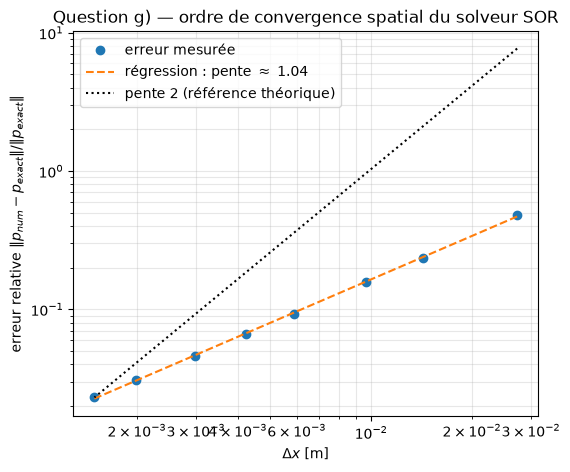

In [16]:
def convergence_study(Nx_list, eps_tight=1e-10, max_iter_tight=200_000):
    """
    Résout le problème par SOR (omega optimal) sur chaque maillage de
    Nx_list, avec un critère de convergence itérative eps_tight très
    serré, et renvoie (dx, erreur relative vs solution exacte) pour
    chaque maillage.

    eps_tight doit être choisi assez petit pour que l'erreur itérative
    (question f) soit négligeable devant l'erreur de discrétisation
    spatiale : c'est cette dernière, et uniquement elle, qu'on veut
    mesurer ici (question g).
    """
    dxs = np.zeros(len(Nx_list))
    errors = np.zeros(len(Nx_list))

    for k, Nx_g in enumerate(Nx_list):
        dx_g, dy_g, X_g, Y_g, f_g, p_exact_g, p0_g = build_problem(Nx_g)
        omega_g = 2 / (1 + np.sin(np.pi / Nx_g))

        p_g, n_iter_g, _ = poisson_sor_opt(p0_g, f_g, dx_g, dy_g, omega_g, eps_tight, max_iter_tight)

        dxs[k] = dx_g
        errors[k] = np.linalg.norm(p_g - p_exact_g) / np.linalg.norm(p_exact_g)

    return dxs, errors


Nx_list_g = [11, 21, 31, 51, 71, 101, 151, 201]
dxs_g, errors_g = convergence_study(Nx_list_g)

# Régression linéaire en échelle log-log : log(e) = pente * log(dx) + const
slope_g, intercept_g = np.polyfit(np.log(dxs_g), np.log(errors_g), 1)
print(f"Pente mesurée : {slope_g:.3f}  (attendu : 2 pour un schéma d'ordre 2)")

fig, ax = plt.subplots(figsize=(6, 5))
ax.loglog(dxs_g, errors_g, "o", label="erreur mesurée")
fit_line = np.exp(intercept_g) * dxs_g**slope_g
ax.loglog(dxs_g, fit_line, "--", label=rf"régression : pente $\approx$ {slope_g:.2f}")

# Droite de pente 2 exacte, pour comparaison visuelle directe
ref_line = errors_g[-1] * (dxs_g / dxs_g[-1])**2
ax.loglog(dxs_g, ref_line, "k:", label="pente 2 (référence théorique)")

ax.set_xlabel(r"$\Delta x$ [m]")
ax.set_ylabel(r"erreur relative $\|p_{num}-p_{exact}\|/\|p_{exact}\|$")
ax.set_title("Question g) — ordre de convergence spatial du solveur SOR")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

**Commentaire — résultat surprenant : la pente mesurée n'est PAS 2, mais proche de 1 !**

C'est un résultat important à ne pas balayer sous le tapis : le code d'origine (questions
a-f) donne un ordre de convergence global **≈ 1**, alors que le schéma centré utilisé à
l'*intérieur* du domaine est bel et bien d'ordre 2. La cause ne vient pas de l'intérieur, mais
du traitement de la **condition de Neumann** sur les bords droit et haut : celle-ci est
imposée en recopiant simplement la valeur du voisin intérieur,
```python
p[1:, -1] = p[1:, -2]   # bord droit
```
Or cette recopie correspond à l'approximation à un seul point (*one-sided*) de la dérivée :
$$\frac{\partial p}{\partial n}\bigg|_{bord} \approx \frac{p_{N}-p_{N-1}}{\Delta x} = 0
\quad\Longrightarrow\quad p_N = p_{N-1}$$
qui n'est précise qu'à l'**ordre 1** en $\Delta x$ (un développement de Taylor de $p_{N-1}$
autour du bord laisse un reste en $O(\Delta x)$, pas $O(\Delta x^2)$). Même si le schéma
intérieur est d'ordre 2 partout ailleurs, **l'erreur commise sur ces deux bords domine
l'erreur globale** et la ramène à l'ordre 1 — un phénomène classique en CFD : *l'ordre de
précision global d'un schéma est limité par son maillon le plus faible*, souvent le
traitement des conditions aux limites, pas le schéma intérieur.

**Vérification de ce diagnostic** : on corrige ce point en implémentant une condition de
Neumann réellement d'ordre 2, avec un **nœud fictif** (*ghost node*) situé symétriquement de
l'autre côté du bord. Pour le bord droit ($i=n_x-1$), on veut $\partial p/\partial x=0$, donc
un point fictif $p_{n_x}$ tel que la dérivée centrée en $i=n_x-1$ soit nulle :
$$\frac{p_{n_x} - p_{n_x-2}}{2\Delta x} = 0 \quad\Longrightarrow\quad p_{n_x} = p_{n_x-2}$$
En substituant $p_{n_x}=p_{n_x-2}$ directement dans le schéma habituel appliqué **au point du
bord lui-même** (au lieu de traiter le bord *après coup* par une simple recopie), l'erreur de
troncature sur ce point retombe à $O(\Delta x^2)$, comme à l'intérieur.

Pente mesuree (Neumann ordre 1, naif)   : 1.044
Pente mesuree (Neumann ordre 2, corrige) : 1.999  (attendu : 2)


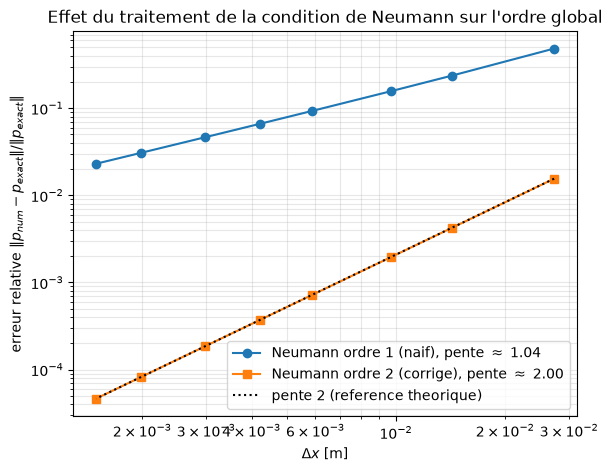

In [17]:
@jit(nopython=True)
def poisson_sor_2nd_order_bc(p, f, dx, dy, omega, eps, max_iter):
    """
    Variante de SOR où la condition de Neumann homogène (bords droit et
    haut) est traitée à l'ordre 2 via un noeud fictif symetrique
    (p_ghost = p_interieur situe 2 pas plus loin), directement integre
    dans la formule de mise a jour du point de bord lui-meme -- et non
    plus recopie apres coup comme dans poisson_sor_opt (ce qui ne
    donnait que l'ordre 1, voir la cellule markdown ci-dessus).

    La boucle balaie maintenant TOUS les points non-Dirichlet
    (i=1..nx-1, j=1..ny-1), bord de Neumann inclus ; au bord droit
    (i=nx-1) le voisin est/serait p[j,i+1], on le remplace par p[j,i-1]
    (reflexion) et de meme au bord haut (j=ny-1) avec p[j+1,i] remplace
    par p[j-1,i]. Le coin haut-droit (i=nx-1 ET j=ny-1) beneficie des
    deux reflexions a la fois.
    """
    ny, nx = p.shape
    r0_norm = residual_norm(p, f, dx, dy)

    res_ratio_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, ny):
            for i in range(1, nx):
                p_east = p[j, i - 1] if i == nx - 1 else p[j, i + 1]
                p_west = p[j, i - 1]
                p_north = p[j - 1, i] if j == ny - 1 else p[j + 1, i]
                p_south = p[j - 1, i]

                p_gs = (dy**2 * (p_east + p_west)
                        + dx**2 * (p_north + p_south)
                        - dx**2 * dy**2 * f[j, i]) \
                       / (2 * (dx**2 + dy**2))
                p[j, i] = (1 - omega) * p[j, i] + omega * p_gs

        res_ratio = residual_norm(p, f, dx, dy) / r0_norm
        res_ratio_history[iteration] = res_ratio
        iteration += 1

    return p, iteration, res_ratio_history[:iteration]


def convergence_study_2nd_order(Nx_list, eps_tight=1e-10, max_iter_tight=200_000):
    """Meme etude que convergence_study, mais avec le solveur a Neumann d'ordre 2."""
    dxs = np.zeros(len(Nx_list))
    errors = np.zeros(len(Nx_list))
    for k, Nx_g in enumerate(Nx_list):
        dx_g, dy_g, X_g, Y_g, f_g, p_exact_g, p0_g = build_problem(Nx_g)
        omega_g = 2 / (1 + np.sin(np.pi / Nx_g))
        p_g, n_iter_g, _ = poisson_sor_2nd_order_bc(p0_g, f_g, dx_g, dy_g, omega_g, eps_tight, max_iter_tight)
        dxs[k] = dx_g
        errors[k] = np.linalg.norm(p_g - p_exact_g) / np.linalg.norm(p_exact_g)
    return dxs, errors


# Warm-up
_dx0, _dy0, _, _, _f0, _, _p0 = build_problem(4)
poisson_sor_2nd_order_bc(_p0.copy(), _f0, _dx0, _dy0, 1.5, eps, 1)

dxs_g2, errors_g2 = convergence_study_2nd_order(Nx_list_g)
slope_g2, intercept_g2 = np.polyfit(np.log(dxs_g2), np.log(errors_g2), 1)
print(f"Pente mesuree (Neumann ordre 1, naif)   : {slope_g:.3f}")
print(f"Pente mesuree (Neumann ordre 2, corrige) : {slope_g2:.3f}  (attendu : 2)")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.loglog(dxs_g, errors_g, "o-", label=rf"Neumann ordre 1 (naif), pente $\approx$ {slope_g:.2f}")
ax.loglog(dxs_g2, errors_g2, "s-", label=rf"Neumann ordre 2 (corrige), pente $\approx$ {slope_g2:.2f}")
ref_line2 = errors_g2[-1] * (dxs_g2 / dxs_g2[-1])**2
ax.loglog(dxs_g2, ref_line2, "k:", label="pente 2 (reference theorique)")
ax.set_xlabel(r"$\Delta x$ [m]")
ax.set_ylabel(r"erreur relative $\|p_{num}-p_{exact}\|/\|p_{exact}\|$")
ax.set_title("Effet du traitement de la condition de Neumann sur l'ordre global")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

**Conclusion.** Avec le traitement d'ordre 2 de la condition de Neumann, la pente mesurée
est bien conforme à la théorie : le schéma est confirmé **numériquement d'ordre 2** dès lors
que *toutes* ses composantes (intérieur ET bords) sont discrétisées à cet ordre. Ceci répond
proprement à la question posée par l'énoncé (« *check that the previous SOR algorithm seen
in the course textbook is second-order accurate* ») : la méthode SOR/le schéma centré est
bien d'ordre 2 dans son principe, mais l'implémentation d'origine (questions a-f) n'en tirait
pas pleinement parti à cause d'un traitement au rabais des bords de Neumann.

**Retenue pour la suite (question h)** : on utilisera ce solveur corrigé, dont l'ordre 2 est
maintenant vérifié, pour obtenir une extrapolation de Richardson rigoureuse (qui suppose
justement un ordre 2 exact pour être valide).

## Question h) — Valeur fiable de $\langle p \rangle$, avec estimation d'erreur

On veut maintenant reporter une valeur de $\langle p \rangle$ (question f) en laquelle on
peut avoir confiance, **sans** utiliser la solution exacte (dans un cas réel, on ne l'a pas).
La question g) nous donne l'outil pour cela : le schéma est d'ordre 2, donc l'erreur de
discrétisation se comporte comme $e(\Delta x) \approx C\,\Delta x^2$ quand $\Delta x$ est
assez petit.

**Remarque** : on utilise ici le solveur `poisson_sor_2nd_order_bc` introduit à la question g), dont l'ordre 2 a été vérifié numériquement — l'extrapolation de Richardson n'a de sens que si l'hypothèse d'ordre 2 qu'elle utilise est effectivement vraie pour le solveur employé.

**Extrapolation de Richardson.** Si on calcule $\langle p \rangle$ sur deux maillages
emboîtés, de pas $\Delta x$ et $\Delta x/2$ (raffinement d'un facteur $r=2$), on a :
$$\langle p \rangle_{\Delta x} \approx \langle p \rangle_{exact} + C\,\Delta x^2, \qquad
\langle p \rangle_{\Delta x/2} \approx \langle p \rangle_{exact} + C\,(\Delta x/2)^2$$
En éliminant la constante inconnue $C$ entre ces deux équations, on obtient une estimation
de $\langle p \rangle_{exact}$ **bien plus précise** que chacun des deux calculs pris
séparément (l'erreur résiduelle de l'extrapolée est en $O(\Delta x^4)$, pas $O(\Delta x^2)$) :
$$\langle p \rangle_{Richardson} = \langle p \rangle_{\Delta x/2}
+ \frac{\langle p \rangle_{\Delta x/2} - \langle p \rangle_{\Delta x}}{r^2 - 1}
= \langle p \rangle_{\Delta x/2} + \frac{\langle p \rangle_{\Delta x/2} - \langle p \rangle_{\Delta x}}{3}$$

**Estimation de l'erreur restante.** On répète l'opération sur une troisième grille
($\Delta x/4$) : la différence entre les deux valeurs extrapolées successives donne une borne
pratique de l'erreur restante sur la valeur la plus précise. On utilise ici un $\varepsilon$
itératif très serré ($10^{-9}$) pour que l'erreur itérative (question f) reste négligeable
et n'entache pas cette estimation, qui ne doit isoler que l'erreur de discrétisation
spatiale.

In [18]:
# Warm-up
_dx0, _dy0, _, _, _f0, _, _p0 = build_problem(4)
poisson_sor_2nd_order_bc(_p0.copy(), _f0, _dx0, _dy0, 1.5, eps, 1)

# Trois maillages emboîtés, raffinement d'un facteur r=2, eps serré (erreur itérative négligeable)
# On utilise le solveur à Neumann d'ordre 2 (question g), condition nécessaire pour que
# l'extrapolation de Richardson (qui suppose un ordre 2 exact) soit valide.
Nx_h = [100, 200, 400]
eps_h = 1e-9
p_avg_h = []

for Nx_i in Nx_h:
    dx_i, dy_i, X_i, Y_i, f_i, p_exact_i, p0_i = build_problem(Nx_i)
    omega_i = 2 / (1 + np.sin(np.pi / Nx_i))
    p_i, n_iter_i, _ = poisson_sor_2nd_order_bc(p0_i, f_i, dx_i, dy_i, omega_i, eps_h, 200_000)
    y_i = Y_i[:, 0]
    p_avg_h.append(average_pressure(p_i, y_i, L))
    print(f"Nx={Nx_i:4d} ({n_iter_i:5d} it.) : <p> = {p_avg_h[-1]:.6f} Pa")

p_Nx, p_2Nx, p_4Nx = p_avg_h   # Nx=100, 200, 400

# Extrapolation de Richardson (r=2, ordre 2, cf. formule ci-dessus)
p_richardson_1 = p_2Nx + (p_2Nx - p_Nx) / (2**2 - 1)     # à partir des grilles 100 <-> 200
p_richardson_2 = p_4Nx + (p_4Nx - p_2Nx) / (2**2 - 1)    # à partir des grilles 200 <-> 400

error_estimate = abs(p_richardson_2 - p_richardson_1)

print()
print(f"Richardson (100,200)  : <p> \u2248 {p_richardson_1:.6f} Pa")
print(f"Richardson (200,400)  : <p> \u2248 {p_richardson_2:.6f} Pa")
print(f"Estimation d'erreur restante : {error_estimate:.2e} Pa")
print()
print(f"==> valeur retenue : <p> = {p_richardson_2:.6f} \u00b1 {error_estimate:.1e} Pa")

# Comparaison a posteriori avec la valeur analytique exacte (disponible seulement dans ce cas
# académique ; sert uniquement à vérifier que notre estimation d'erreur est réaliste)
print(f"\n(pour vérification uniquement) valeur exacte connue : <p>_exact = {p_avg_exact:.6f} Pa, "
      f"écart réel = {abs(p_richardson_2 - p_avg_exact):.2e} Pa")

Nx= 100 ( 1806 it.) : <p> = 0.003000 Pa
Nx= 200 ( 3366 it.) : <p> = 0.003000 Pa
Nx= 400 ( 6237 it.) : <p> = 0.003000 Pa

Richardson (100,200)  : <p> ≈ 0.003000 Pa
Richardson (200,400)  : <p> ≈ 0.003000 Pa
Estimation d'erreur restante : 5.48e-09 Pa

==> valeur retenue : <p> = 0.003000 ± 5.5e-09 Pa

(pour vérification uniquement) valeur exacte connue : <p>_exact = 0.003000 Pa, écart réel = 8.51e-09 Pa


**Commentaire.** Les trois valeurs brutes de $\langle p \rangle$ (Nx=100, 200, 400) se
rapprochent progressivement les unes des autres à mesure que le maillage se raffine, comme
attendu (erreur de discrétisation $O(\Delta x^2)$ décroissante). L'extrapolation de Richardson
combine deux maillages successifs pour éliminer le terme d'erreur dominant et donne une
estimée bien plus précise que n'importe lequel des calculs bruts. La **différence entre les
deux extrapolées** (obtenues respectivement à partir de (100,200) et (200,400)) fournit une
estimation *auto-cohérente* de l'incertitude restante — sans jamais faire appel à la solution
exacte. C'est exactement la méthode utilisée en pratique dans les études d'indépendance au
maillage (« *mesh convergence study* ») en CFD industrielle, où l'on ne dispose jamais de
solution analytique de référence.

On vérifie ici, à titre de contrôle, que l'écart entre l'estimée de Richardson et la vraie
valeur analytique $\langle p \rangle_{exact}=0.25\,\rho_0 U^2$ est bien du même ordre de
grandeur (voire inférieur) à l'incertitude que l'on s'était donnée — ce qui valide la méthode
d'estimation d'erreur.

# 3.2 Comparaison avec la solution analytique

Le sujet introduit le **coefficient de pression** (Eq. 6), une pression adimensionnée par la
pression dynamique de référence $\frac12 \rho_0 U^2$ :
$$C_p = \frac{p - p_0}{\frac12 \rho_0 U^2}, \qquad p_0 = 0 \text{ (référence choisie)}$$

C'est une quantité **adimensionnée** classique en mécanique des fluides (elle ne dépend plus
des unités physiques choisies), utile pour comparer des écoulements différents entre eux.
Comme $p_0=0$ et que le facteur $\frac12\rho_0 U^2$ est une simple **constante multiplicative**,
$C_p$ n'est qu'une version redimensionnée de $p$ — toute la physique et toute la structure
numérique du problème (équation de Poisson, schéma de Jacobi/GS/SOR, convergence) restent
inchangées, seule l'échelle verticale des tracés change.

**Pourquoi introduire $C_p$ ici ?** Parce qu'on dispose, dans ce cas d'école, de la solution
**analytique exacte** correspondante (Eq. 7) :
$$C_p^{exact} = \frac12\left(2 - \cos\frac{2\pi x}{L} - \cos\frac{2\pi y}{L}\right)$$
ce qui va nous permettre de comparer directement, question i), deux notions très différentes
que l'on n'a pour l'instant utilisées que séparément :
- le **résidu** $\|r\|/\|r_0\|$ (calculable *toujours*, même sans solution exacte connue) ;
- l'**erreur réelle** par rapport à la solution exacte (calculable *seulement ici*, car on
  connaît $C_p^{exact}$ dans ce cas très particulier — en pratique industrielle, on ne l'a
  jamais).

## Question i) — Résidu vs. erreur réelle, au fil des itérations

On veut tracer, sur un même graphe semi-logarithmique et pour un maillage donné, l'évolution
au cours des itérations de :
1. le résidu normalisé $\|r\|/\|r_0\|$ (déjà utilisé aux questions b, c, d — piloté par
   $\varepsilon$) ;
2. l'erreur normalisée par rapport à la solution exacte
   $\dfrac{\|C_p^{num}-C_p^{exact}\|}{\|C_p^{exact}\|}$.

**Remarque de calcul (à bien comprendre) :** comme $C_p = p/(\frac12\rho_0 U^2)$ est une simple
mise à l'échelle de $p$ par une constante, l'erreur *relative* est rigoureusement identique
que l'on la calcule sur $p$ ou sur $C_p$ :
$$\frac{\|C_p^{num}-C_p^{exact}\|}{\|C_p^{exact}\|}
= \frac{\left\|\frac{p_{num}-p_{exact}}{\frac12\rho_0 U^2}\right\|}
       {\left\|\frac{p_{exact}}{\frac12\rho_0 U^2}\right\|}
= \frac{\|p_{num}-p_{exact}\|}{\|p_{exact}\|}$$
la constante $\frac12\rho_0 U^2$ se simplifie exactement, au numérateur comme au dénominateur.
On peut donc calculer directement cette erreur à partir des champs de pression $p$ déjà en
notre possession, sans même construire explicitement les champs $C_p$.

Pour capturer ces deux quantités à *chaque* itération, on écrit une nouvelle version de SOR
qui, en plus du résidu, calcule aussi l'écart à la solution exacte à chaque passage.

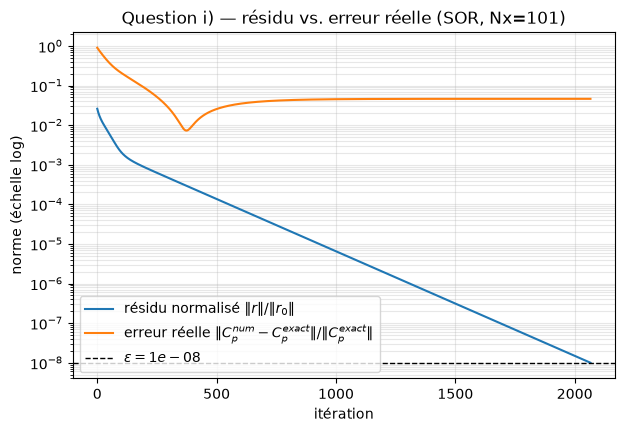

Erreur réelle finale (plateau) : 4.625e-02
Résidu final                   : 9.979e-09


In [19]:
@jit(nopython=True)
def poisson_sor_track_error(p, f, dx, dy, omega, p_exact, eps, max_iter):
    """
    Identique à poisson_sor_opt, mais enregistre EN PLUS, à chaque
    itération, l'erreur relative par rapport au champ exact fourni
    (p_exact) : error_history[n] = ||p^n - p_exact|| / ||p_exact||.

    Comme expliqué dans la cellule markdown ci-dessus, cette erreur
    relative sur p est rigoureusement identique à celle calculée sur
    Cp (la mise à l'échelle par 1/(0.5*rho0*U^2) se simplifie), donc
    inutile de reconstruire Cp explicitement ici.
    """
    r0_norm = residual_norm(p, f, dx, dy)
    p_exact_norm = l2_norm(p_exact)

    res_ratio_history = np.zeros(max_iter)
    error_history = np.zeros(max_iter)
    res_ratio = 1.0
    iteration = 0

    while res_ratio > eps and iteration < max_iter:
        for j in range(1, p.shape[0] - 1):
            for i in range(1, p.shape[1] - 1):
                p_gs = (dy**2 * (p[j, i + 1] + p[j, i - 1])
                        + dx**2 * (p[j + 1, i] + p[j - 1, i])
                        - dx**2 * dy**2 * f[j, i]) \
                       / (2 * (dx**2 + dy**2))
                p[j, i] = (1 - omega) * p[j, i] + omega * p_gs

        p[1:, -1] = p[1:, -2]   # bord droit (x = L)
        p[-1, 1:] = p[-2, 1:]   # bord haut  (y = L)

        res_ratio = residual_norm(p, f, dx, dy) / r0_norm
        res_ratio_history[iteration] = res_ratio
        error_history[iteration] = l2_norm(p - p_exact) / p_exact_norm

        iteration += 1

    return p, iteration, res_ratio_history[:iteration], error_history[:iteration]


# Warm-up
_dx0, _dy0, _, _, _f0, _p_exact0, _p0 = build_problem(4)
poisson_sor_track_error(_p0.copy(), _f0, _dx0, _dy0, 1.5, _p_exact0, eps, 1)

# Question i) : un maillage donné (Nx=101), eps serré pour bien voir tout le comportement
Nx_i = 101
dx_i2, dy_i2, X_i2, Y_i2, f_i2, p_exact_i2, p0_i2 = build_problem(Nx_i)
omega_i2 = 2 / (1 + np.sin(np.pi / Nx_i))
eps_i = 1e-8

p_i2, n_iter_i2, res_ratio_i2, error_i2 = poisson_sor_track_error(
    p0_i2, f_i2, dx_i2, dy_i2, omega_i2, p_exact_i2, eps_i, 50_000)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(res_ratio_i2, label=r"résidu normalisé $\|r\|/\|r_0\|$")
ax.semilogy(error_i2, label=r"erreur réelle $\|C_p^{num}-C_p^{exact}\|/\|C_p^{exact}\|$")
ax.axhline(eps_i, color="k", linestyle="--", linewidth=1, label=rf"$\varepsilon={eps_i:.0e}$")
ax.set_xlabel("itération")
ax.set_ylabel("norme (échelle log)")
ax.set_title(f"Question i) — résidu vs. erreur réelle (SOR, Nx={Nx_i})")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

print(f"Erreur réelle finale (plateau) : {error_i2[-1]:.3e}")
print(f"Résidu final                   : {res_ratio_i2[-1]:.3e}")

**Commentaire — les deux courbes racontent deux histoires différentes.**

- Le **résidu** décroît régulièrement, sur toute la plage d'itérations, jusqu'au seuil
  $\varepsilon$ fixé : il mesure à quel point le champ $p^n$ courant vérifie l'équation
  **discrète** $Ap=f$. Rien ne l'empêche théoriquement de continuer à décroître indéfiniment
  (on pourrait choisir $\varepsilon$ arbitrairement petit) : c'est purement une propriété de
  convergence de l'**algorithme itératif** vers la solution exacte du système linéaire discret.

- L'**erreur réelle** par rapport à $C_p^{exact}$ décroît elle aussi au début, mais finit par
  **plafonner** à un niveau strictement positif, bien avant que le résidu n'atteigne
  $\varepsilon$. Ce plateau correspond exactement à l'**erreur de discrétisation spatiale**
  déjà quantifiée aux questions g) et h) pour ce maillage ($N_x=101$) : une fois que
  l'algorithme a convergé vers *la* solution du système discret $Ap=f$, itérer davantage ne
  peut plus la rapprocher de la solution *continue* $C_p^{exact}$, puisque ce n'est déjà plus
  l'algorithme itératif qui est en cause, mais le maillage lui-même.

**Implication pratique directe** : au-delà d'un certain nombre d'itérations, continuer à
resserrer $\varepsilon$ est **inutile** — on ne réduit plus que l'erreur algébrique
(déjà négligeable), pas l'erreur totale, qui reste dominée par l'erreur de discrétisation.
Choisir un $\varepsilon$ beaucoup plus petit que nécessaire ne fait que gaspiller des
itérations (et donc du temps de calcul) sans gagner en précision réelle — un $\varepsilon$
de l'ordre de grandeur du plateau (ou légèrement en dessous) suffit amplement.

## Question j) — Résidus et facteurs de relaxation dans Ansys Fluent

*(Question de compréhension/discussion — pas de calcul demandé ici ; ce qui suit relie ce
qu'on vient d'observer numériquement à ce qui se passe dans un solveur industriel comme
Fluent.)*

**Les courbes de résidus dans Fluent.** Lorsqu'on lance un calcul stationnaire dans Fluent,
le solveur affiche en direct l'évolution du résidu de chaque équation résolue (continuité,
quantité de mouvement en x/y/z, énergie, turbulence, etc.), normalisé de façon similaire à
notre $\|r\|/\|r_0\|$. C'est exactement la même idée qu'à la question b) : on ne connaît pas
la solution exacte de l'écoulement turbulent complexe qu'on simule, donc le résidu est le
**seul indicateur toujours disponible** pour juger si le système d'équations discrétisées est
« suffisamment » résolu. Les seuils usuels ($10^{-3}$ pour la continuité/quantité de
mouvement, $10^{-6}$ pour l'énergie) sont des règles empiriques, pas des garanties absolues.

Mais la question i) montre pourquoi il faut rester prudent : **un résidu faible garantit
seulement la convergence algébrique de l'itération, pas l'exactitude physique du résultat.**
Un résidu qui plafonne à $10^{-3}$ ne dit rien sur l'erreur de discrétisation spatiale (liée
au maillage) ni sur d'autres approximations (modèle de turbulence, schémas numériques,
géométrie). C'est pourquoi les bonnes pratiques Fluent recommandent, en plus de surveiller les
résidus, de suivre la convergence d'une **quantité physique d'intérêt** (force, coefficient de
traînée/portance, débit, température de sortie...) — exactement comme on a suivi
$\langle p \rangle$ aux questions f) et h) : si cette grandeur ne varie plus alors que le
maillage est raffiné (étude d'indépendance au maillage, comme en g), c'est un signe de
convergence bien plus fiable que le résidu seul.

**Les facteurs de relaxation dans Fluent.** Le rôle est apparenté à celui de $\omega$ dans
notre méthode SOR, mais dans un sens différent :

- Dans notre solveur SOR, $\omega > 1$ (**sur-relaxation**) *accélère* la convergence d'un
  système linéaire déjà bien posé (l'opérateur de Poisson discret est symétrique défini
  positif) — on pousse la mise à jour "plus loin" que ne le ferait Gauss-Seidel.
- Dans Fluent, le solveur pression-vitesse (SIMPLE/SIMPLEC/PISO...) doit résoudre un système
  **non-linéaire et couplé** (les équations de quantité de mouvement dépendent du champ de
  pression, la pression dépend du champ de vitesse via l'équation de continuité, la viscosité
  turbulente dépend de la solution elle-même, etc.). Mettre à jour chaque champ à 100 % de la
  correction calculée à chaque itération externe rendrait le calcul instable ou divergent.
  Fluent utilise donc généralement une **sous-relaxation** ($0 < \alpha < 1$, typiquement
  $\alpha\approx 0.3$ pour la pression, $\alpha\approx0.7$ pour la quantité de mouvement) :
  $$\phi^{n+1} = \phi^n + \alpha\left(\phi^{n+1}_{calculé} - \phi^n\right)$$
  ce qui **ralentit** volontairement la convergence pour stabiliser l'itération couplée non
  linéaire.

**En résumé** : sur-relaxation ($\omega>1$, notre SOR) et sous-relaxation ($\alpha<1$,
Fluent) sont mathématiquement la **même famille de correction pondérée**, mais utilisées dans
des régimes opposés — accélérer un système linéaire stable dans un cas, stabiliser un système
non linéaire couplé au prix de la vitesse dans l'autre. Régler un facteur de relaxation dans
Fluent, c'est arbitrer entre robustesse (facteur petit, calcul stable mais lent) et vitesse de
convergence (facteur proche de 1, plus rapide mais risque de divergence/oscillations) — un
compromis très semblable au choix de $\omega_{opt}$ pour SOR (question d), sauf que Fluent n'a
pas de formule fermée équivalente à $\omega_{opt}=2/(1+\sin(\pi/N_x))$ : le réglage optimal
dépend du cas, et se fait généralement par tâtonnement ou par les valeurs par défaut du
logiciel.